In [1]:
import pandas as pd

# Charger les données nettoyées
df = pd.read_csv(
    "../data/retail_store_sales_clean.csv",
    parse_dates=["Transaction Date"]
)

# Vérifier le chargement
print("Dimensions du jeu de données :", df.shape)
display(df.head())

Dimensions du jeu de données : (12575, 11)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


# 1. Analyse des données

Cette partie a pour objectif d'analyser les données nettoyées afin d'étudier les ventes, les produits, les clients et leur évolution dans le temps.

## 1.1 Indicateurs généraux des ventes

In [2]:
# Calcul des indicateurs généraux

nb_transactions = df["Transaction ID"].nunique()
nb_clients = df["Customer ID"].nunique()
nb_categories = df["Category"].nunique()

chiffre_affaires = df["Total Spent"].sum()
panier_moyen = df["Total Spent"].mean()
quantite_totale = df["Quantity"].sum()

print("Nombre de transactions :", nb_transactions)
print("Nombre de clients :", nb_clients)
print("Nombre de catégories :", nb_categories)
print("Chiffre d'affaires total :", round(chiffre_affaires, 2))
print("Montant moyen par transaction :", round(panier_moyen, 2))
print("Quantité totale vendue :", quantite_totale)

Nombre de transactions : 12575
Nombre de clients : 25
Nombre de catégories : 8
Chiffre d'affaires total : 1552071.0
Montant moyen par transaction : 129.65
Quantité totale vendue : 66276.0


**Interprétation des indicateurs généraux**

L'analyse générale montre que le jeu de données contient 12 575 transactions, réalisées par 25 clients et réparties dans 8 catégories. Le chiffre d'affaires connu s'élève à 1 552 071, avec un panier moyen de 129,65. La quantité totale vendue est de 66 276 unités.

## 1.2 Analyse des ventes par catégorie

In [3]:
# Analyse des ventes par catégorie

ventes_categorie = df.groupby("Category").agg(
    Nombre_transactions=("Transaction ID", "nunique"),
    Chiffre_affaires=("Total Spent", "sum"),
    Quantite_vendue=("Quantity", "sum")
).reset_index()

ventes_categorie = ventes_categorie.sort_values(
    by="Chiffre_affaires",
    ascending=False
)

display(ventes_categorie)

,Category,Nombre_transactions,Chiffre_affaires,Quantite_vendue
1,Butchers,1568,208118.0,8206.0
3,Electric household essentials,1591,203813.5,8309.0
0,Beverages,1567,197047.5,8358.0
5,Furniture,1591,195310.0,8462.0
4,Food,1588,194812.0,8387.0
2,Computers and electric accessories,1558,190692.5,8272.0
7,Patisserie,1528,182165.5,7943.0
6,Milk Products,1584,180112.0,8339.0


**Interprétation des ventes par catégorie**

L'analyse montre que la catégorie Butchers génère le chiffre d'affaires le plus élevé avec 208 118, suivie de Electric household essentials avec 203 813,50. À l'inverse, Milk Products présente le chiffre d'affaires le plus faible avec 180 112. Les performances restent relativement proches entre les différentes catégories.

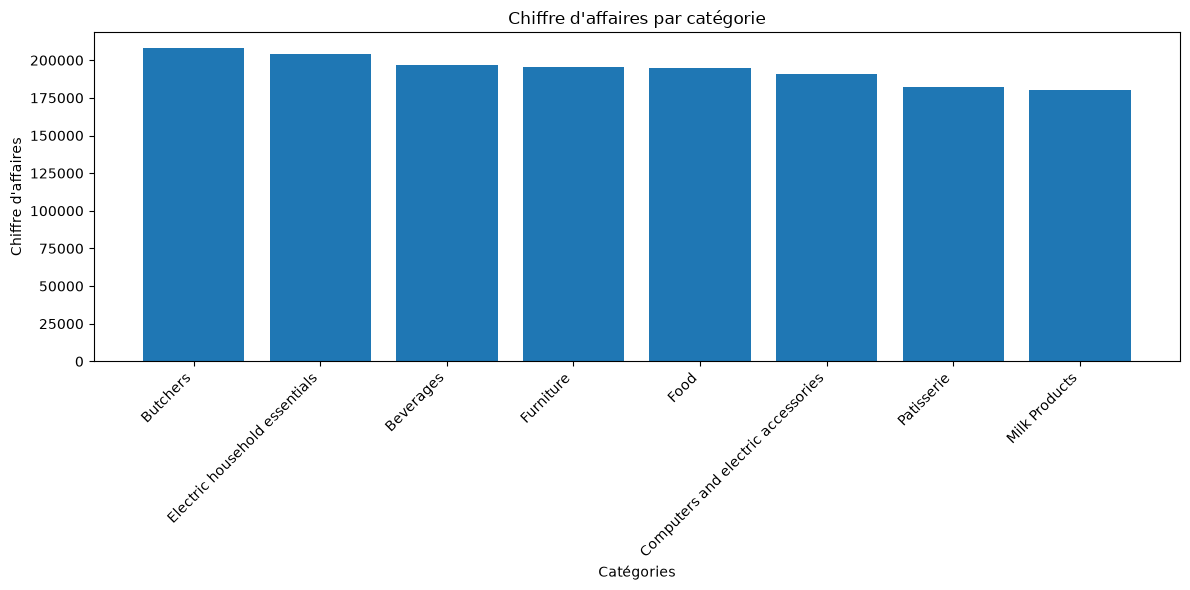

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(
    ventes_categorie["Category"],
    ventes_categorie["Chiffre_affaires"]
)

plt.title("Chiffre d'affaires par catégorie")
plt.xlabel("Catégories")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Enregistrer le graphique
plt.savefig("../figures/chiffre_affaires_par_categorie.png", dpi=300, bbox_inches="tight")

plt.show()